# Spatial Transcriptomics Analysis Template

| Field | Value |
|---|---|
| **Sample** | Visium H&E mouse brain (squidpy built-in) |
| **Date** | *10/26/2026* |
| **Author** | CH |
| **Kernel** | env_spatial |
| **Modality** | 10x Visium (array-based) |
| **Notes** | Template validation run |

---

## Workflow overview

1. Imports and configuration
2. Data loading
3. Quality control
4. Filtering
5. Normalisation and feature selection
6. Dimensionality reduction
7. Clustering
8. Spatial visualisation
9. Spatially variable genes
10. Neighbourhood enrichment
11. Marker identification
12. Automated annotation (CellTypist)
13. Summary export

All decisions recorded in `summaries/spatial_summary.json`.

In [1]:
import os
import json
import warnings
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import median_abs_deviation
from datetime import datetime
import session_info2

warnings.filterwarnings('ignore')

# ── Reproducibility ───────────────────────────────────────────────────────────
SEED = 42
np.random.seed(SEED)

# ── CHANGE THIS FOR EVERY RUN ─────────────────────────────────────────────────
SAMPLE_ID = "visium_hne_test"   # e.g. "lung_visium_s01", "visium_hne_test"

# ── Paths ─────────────────────────────────────────────────────────────────────
BASE_DIR    = f"/home/jovyan/work/analyses/{SAMPLE_ID}"
FIG_DIR     = f"{BASE_DIR}/figures"
CKPT_DIR    = f"{BASE_DIR}/checkpoints"
SUMMARY_DIR = f"{BASE_DIR}/summaries"

for d in [FIG_DIR, CKPT_DIR, SUMMARY_DIR]:
    os.makedirs(d, exist_ok=True)

sc.settings.figdir = FIG_DIR
sc.settings.verbosity = 2

# ── Parameters ────────────────────────────────────────────────────────────────
PARAMS = {
    "sample_id"          : SAMPLE_ID,
    "seed"               : SEED,
    "date"               : datetime.today().strftime('%Y-%m-%d'),
    "author"             : "CH",
    "modality"           : "visium",
    # QC — None = MAD-based automatic threshold
    "min_genes"          : None,
    "max_pct_mt"         : None,
    "max_pct_hb"         : None,
    "mad_nmads"          : 5,
    # Feature selection
    "n_hvgs"             : 3000,
    "hvg_flavor"         : "seurat",
    # Dimensionality reduction
    "n_pcs"              : 50,
    "n_pcs_use"          : 30,
    "n_neighbours"       : 30,
    # Clustering
    "leiden_resolutions" : [0.3, 0.5, 0.8, 1.0],
    "leiden_final"       : 0.5,
    # Spatial analyses
    "n_svgs"             : 1000,    # spatially variable genes to compute
    "n_rings"            : 2,       # neighbourhood enrichment rings
    # Annotation
    "run_celltypist"     : False,    #Temporarily skip CellTypist as it is not in env_spatial
    "celltypist_model"   : "Mouse_Brain_Atlas.pkl",
}

print(f"Configuration loaded.")
print(f"  Sample:   {PARAMS['sample_id']}")
print(f"  Date:     {PARAMS['date']}")
print(f"  Seed:     {PARAMS['seed']}")
print(f"  Base dir: {BASE_DIR}")

Configuration loaded.
  Sample:   visium_hne_test
  Date:     2026-10-26
  Seed:     42
  Base dir: /home/jovyan/work/analyses/visium_hne_test


/opt/conda/envs/env_spatial/lib/python3.12/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/opt/conda/envs/env_spatial/lib/python3.12/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


---
## 2. Data loading

For real Visium data replace `sq.datasets.visium_hne_adata()` with:
```python
adata = sc.read_visium(path_to_spaceranger_output)
```

For Visium HD, load manually from spaceranger parquet outputs:
```python
adata = sc.read_10x_h5("filtered_feature_bc_matrix.h5")
positions = pd.read_parquet("tissue_positions.parquet").set_index("barcode")
adata.obsm["spatial"] = positions[["pxl_col_in_fullres", "pxl_row_in_fullres"]].values
```

The key requirement is that `adata.obsm["spatial"]` contains x/y pixel coordinates.

In [2]:
# Load built-in Visium H&E dataset (mouse brain)
# Replace with sc.read_visium() for real data
img = sq.datasets.visium_hne_image()
adata = sq.datasets.visium_hne_adata()

# Extract image correctly — squeeze the z dimension
hires_img = img.data["image"].squeeze("z").values
adata.uns["spatial"]["V1_Adult_Mouse_Brain"]["images"]["hires"] = hires_img
print(f"Image shape: {hires_img.shape}")

adata.var_names_make_unique()
adata.layers["counts"] = adata.X.copy()

cell_counts = pd.DataFrame(columns=["step", "n_spots", "n_genes", "spots_removed", "notes"])

def record_counts(adata, step, notes="", prev_n=None):
    removed = (prev_n - adata.n_obs) if prev_n is not None else 0
    row = pd.DataFrame([{
        "step"          : step,
        "n_spots"       : adata.n_obs,
        "n_genes"       : adata.n_vars,
        "spots_removed" : removed,
        "notes"         : notes,
    }])
    return pd.concat([cell_counts, row], ignore_index=True)

cell_counts = record_counts(adata, "Raw", "Input count matrix")

print(f"Loaded: {adata.n_obs} spots × {adata.n_vars} genes")
print(adata)

Adding image layer `image`
Image shape: (11757, 11291, 3)
Loaded: 2688 spots × 18078 genes
AnnData object with n_obs × n_vars = 2688 × 18078
    obs: 'in_tissue', 'array_row', 'array_col', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_counts', 'leiden', 'cluster'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'cluster_colors', 'hvg', 'leiden', 'leiden_colors', 'neighbors', 'pca', 'rank_genes_groups', 'spatial', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'
    layers: None (.X), 'cou

---
## 3. Quality control

### 3.1 Flag QC gene sets

Prefixes differ by species:
- Human: MT- / HBA / HBB
- Mouse: mt- / Hba / Hbb

Visium HD bins contain fewer cells per spot than standard Visium — 
QC thresholds are typically lower for HD data.

In [3]:
# Adjust prefixes for your organism
# This dataset is mouse brain
adata.var["mt"]   = adata.var_names.str.startswith("mt-")
adata.var["hb"]   = adata.var_names.str.startswith(("Hba", "Hbb"))
adata.var["ribo"] = adata.var_names.str.startswith(("Rps", "Rpl"))

print(f"Mitochondrial genes : {adata.var['mt'].sum()}")
print(f"Haemoglobin genes   : {adata.var['hb'].sum()}")
print(f"Ribosomal genes     : {adata.var['ribo'].sum()}")

Mitochondrial genes : 13
Haemoglobin genes   : 5
Ribosomal genes     : 101


In [4]:
sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["mt", "hb", "ribo"],
    percent_top=None,
    log1p=False,
    inplace=True
)

print("── QC summary ──────────────────────────────────────────")
print(adata.obs[[
    "total_counts",
    "n_genes_by_counts",
    "pct_counts_mt",
    "pct_counts_hb",
    "pct_counts_ribo"
]].describe().round(2))

── QC summary ──────────────────────────────────────────
       total_counts  n_genes_by_counts  pct_counts_mt  pct_counts_hb  \
count       2688.00             2688.0        2688.00        2688.00   
mean        6690.86             5733.6           0.97           0.18   
std          851.62             1459.5           0.18           0.08   
min         3031.89             1461.0           0.55           0.04   
25%         6186.07             4749.5           0.85           0.13   
50%         6838.48             5805.0           0.92           0.16   
75%         7308.46             6754.0           1.04           0.21   
max         8852.81            10683.0           2.21           0.66   

       pct_counts_ribo  
count          2688.00  
mean              3.89  
std               0.61  
min               2.65  
25%               3.43  
50%               3.79  
75%               4.24  
max               7.75  


### 3.2 MAD-based thresholds

For spatial data, QC is performed on spots/bins rather than cells.
The same MAD approach applies — thresholds are data-driven per sample.

In [5]:
def mad_threshold(series, nmads=5, lower=True, upper=True):
    med = np.median(series)
    mad = median_abs_deviation(series)
    lo  = med - nmads * mad if lower else -np.inf
    hi  = med + nmads * mad if upper else  np.inf
    return lo, hi, med, mad

nmads = PARAMS["mad_nmads"]

lo_genes, hi_genes, _, _ = mad_threshold(adata.obs["n_genes_by_counts"], nmads)
_,        hi_mt,   _, _ = mad_threshold(adata.obs["pct_counts_mt"],      nmads, lower=False)
_,        hi_hb,   _, _ = mad_threshold(adata.obs["pct_counts_hb"],      nmads, lower=False)

thresholds = {
    "min_genes"  : PARAMS["min_genes"]   if PARAMS["min_genes"]   else max(200, lo_genes),
    "max_genes"  : hi_genes,
    "max_pct_mt" : PARAMS["max_pct_mt"]  if PARAMS["max_pct_mt"]  else min(20, hi_mt),
    "max_pct_hb" : PARAMS["max_pct_hb"]  if PARAMS["max_pct_hb"]  else min(5,  hi_hb),
}

print(f"QC thresholds (MAD method, N={nmads}):")
for k, v in thresholds.items():
    src = "manual" if PARAMS.get(k) else "MAD-derived"
    print(f"  {k:<14}: {v:.1f}  ({src})")

QC thresholds (MAD method, N=5):
  min_genes     : 745.0  (MAD-derived)
  max_genes     : 10865.0  (MAD-derived)
  max_pct_mt    : 1.4  (MAD-derived)
  max_pct_hb    : 0.4  (MAD-derived)


### 3.3 QC distributions

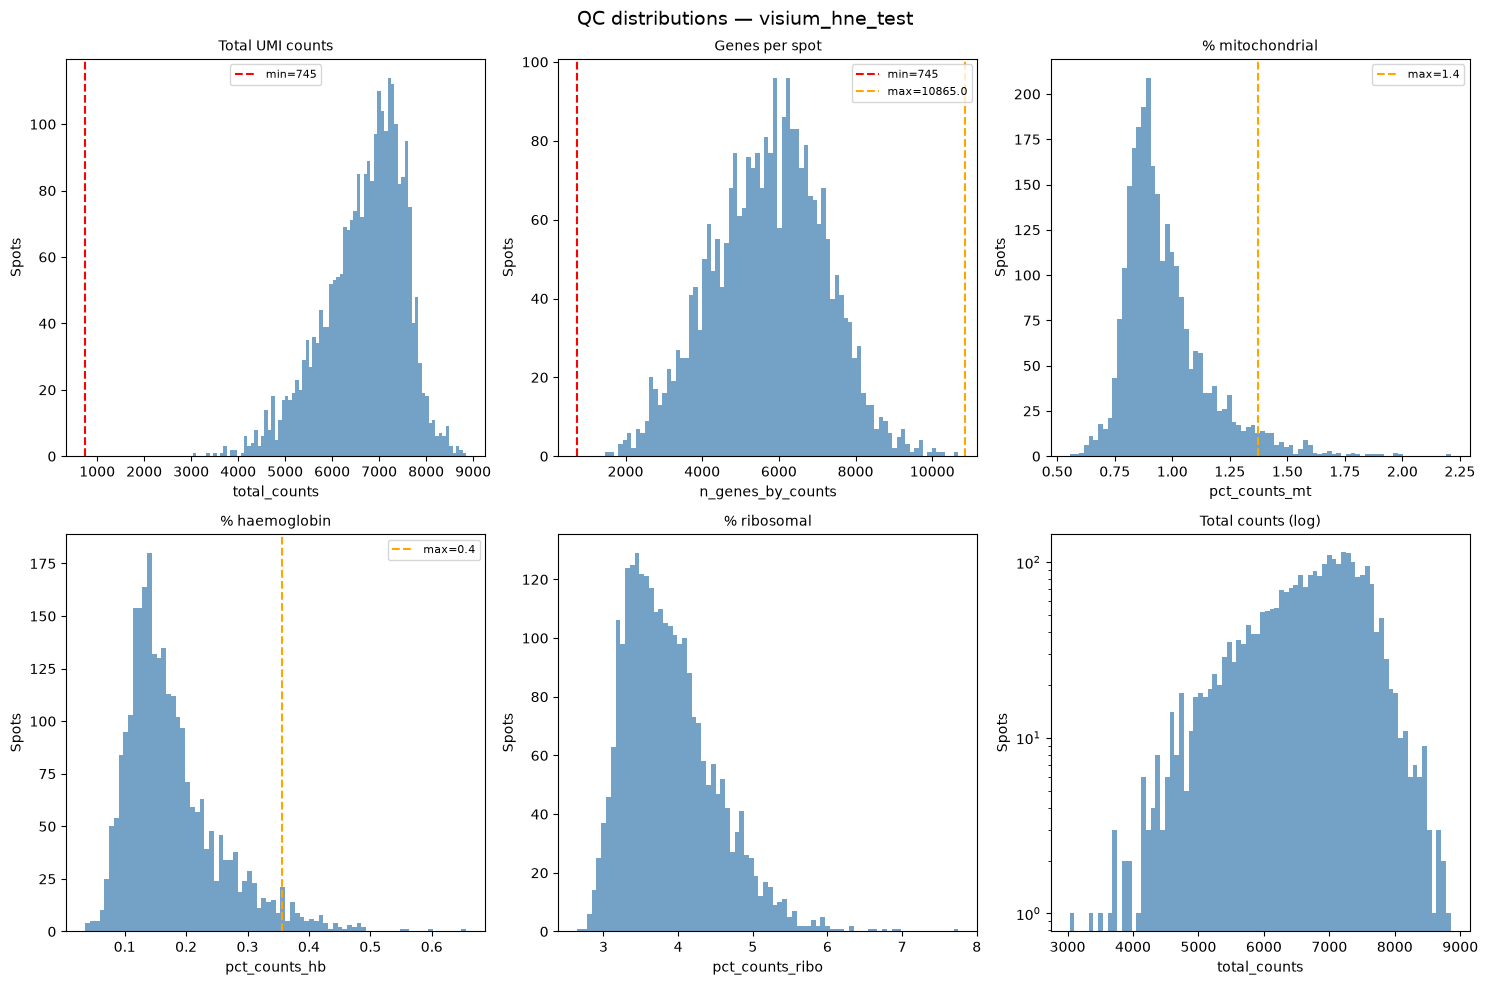

Saved: 01_qc_distributions.png


In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
fig.suptitle(f"QC distributions — {SAMPLE_ID}", fontsize=14)

metrics = [
    ("total_counts",      "Total UMI counts",     None,  thresholds["min_genes"],  None),
    ("n_genes_by_counts", "Genes per spot",        None,  thresholds["min_genes"],  thresholds["max_genes"]),
    ("pct_counts_mt",     "% mitochondrial",       None,  None,                     thresholds["max_pct_mt"]),
    ("pct_counts_hb",     "% haemoglobin",         None,  None,                     thresholds["max_pct_hb"]),
    ("pct_counts_ribo",   "% ribosomal",           None,  None,                     None),
    ("total_counts",      "Total counts (log)",    "log", None,                     None),
]

for ax, (metric, title, yscale, lo, hi) in zip(axes.flat, metrics):
    ax.hist(adata.obs[metric], bins=80, color="steelblue", alpha=0.75, edgecolor="none")
    if lo: ax.axvline(lo, color="red",    ls="--", lw=1.5, label=f"min={lo:.0f}")
    if hi: ax.axvline(hi, color="orange", ls="--", lw=1.5, label=f"max={hi:.1f}")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel(metric)
    ax.set_ylabel("Spots")
    if yscale == "log": ax.set_yscale("log")
    if lo or hi: ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/01_qc_distributions.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: 01_qc_distributions.png")

### 3.4 Spatial QC plots

Overlay QC metrics on tissue to identify spatially structured artefacts.
Low-quality regions often cluster at tissue edges or around tears.

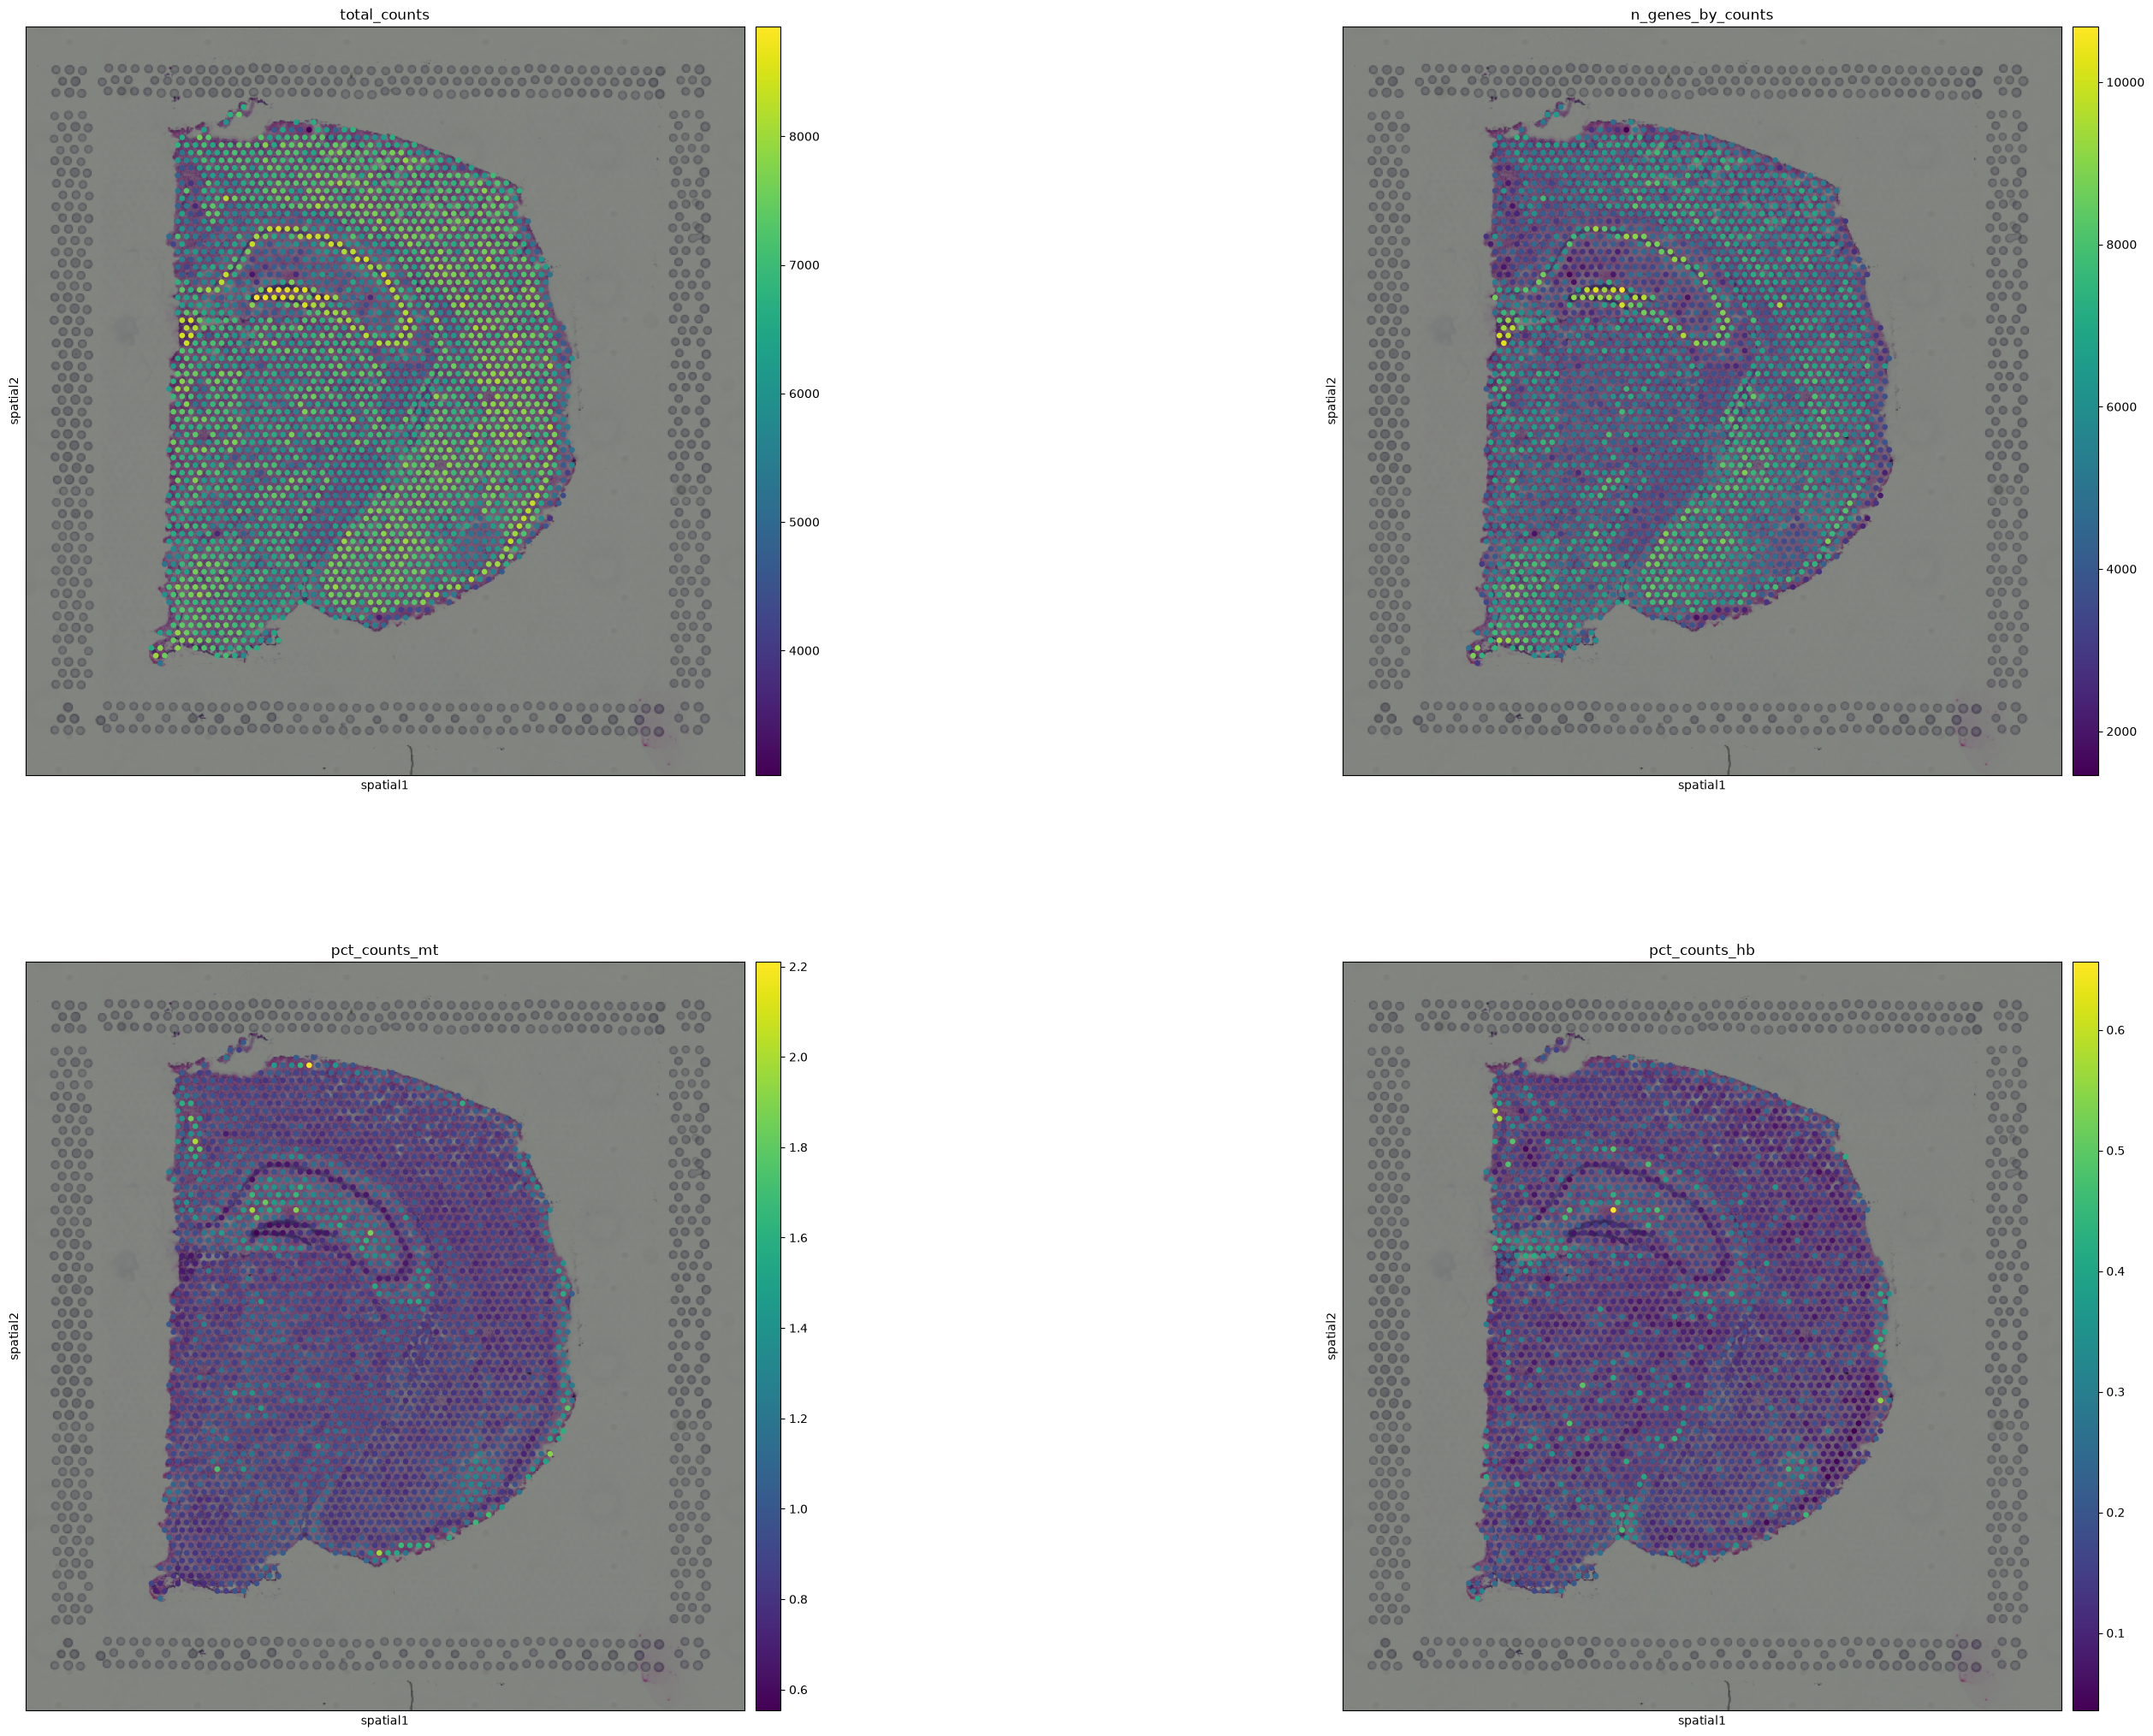

Saved: 02_spatial_qc.png


In [7]:
sq.pl.spatial_scatter(
    adata,
    color=["total_counts", "n_genes_by_counts", "pct_counts_mt", "pct_counts_hb"],
    ncols=2,
    figsize=(16, 12),
    img_res_key="lowres",
)
plt.savefig(f"{FIG_DIR}/02_spatial_qc.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: 02_spatial_qc.png")

---
## 4. Filtering

In [8]:
n_before = adata.n_obs
sc.pp.filter_genes(adata, min_cells=3)
print(f"Gene filter (min_cells=3): {adata.n_vars} genes retained")

cell_counts = record_counts(adata, "Post gene filter", "min_cells=3", n_before)

filters = [
    ("n_genes_by_counts", ">=", thresholds["min_genes"],   "low genes"),
    ("n_genes_by_counts", "<=", thresholds["max_genes"],   "high genes"),
    ("pct_counts_mt",     "<=", thresholds["max_pct_mt"],  "high mt%"),
    ("pct_counts_hb",     "<=", thresholds["max_pct_hb"],  "high hb%"),
]

for metric, op, threshold, reason in filters:
    n_before = adata.n_obs
    if op == ">=":
        adata = adata[adata.obs[metric] >= threshold].copy()
    elif op == "<=":
        adata = adata[adata.obs[metric] <= threshold].copy()
    cell_counts = record_counts(
        adata, f"Filter: {reason}",
        f"{metric} {op} {threshold:.1f}", n_before
    )
    print(f"  {reason:<38}: {adata.n_obs:>5} spots remaining  (removed {n_before - adata.n_obs})")

print(f"\nPost-filtering: {adata.n_obs} spots × {adata.n_vars} genes")
print("\n── Spot count tracking ──────────────────────────────────")
print(cell_counts.to_string(index=False))

adata.write(f"{CKPT_DIR}/01_filtered.h5ad")
print("\nCheckpoint saved: 01_filtered.h5ad")

Gene filter (min_cells=3): 18078 genes retained
  low genes                             :  2688 spots remaining  (removed 0)
  high genes                            :  2688 spots remaining  (removed 0)
  high mt%                              :  2577 spots remaining  (removed 111)
  high hb%                              :  2498 spots remaining  (removed 79)

Post-filtering: 2498 spots × 18078 genes

── Spot count tracking ──────────────────────────────────
              step n_spots n_genes spots_removed                        notes
               Raw    2688   18078             0           Input count matrix
  Post gene filter    2688   18078             0                  min_cells=3
 Filter: low genes    2688   18078             0   n_genes_by_counts >= 745.0
Filter: high genes    2688   18078             0 n_genes_by_counts <= 10865.0
  Filter: high mt%    2577   18078           111         pct_counts_mt <= 1.4
  Filter: high hb%    2498   18078            79         pct_counts_hb <

---
## 5. Normalisation and feature selection

normalizing counts per cell
    finished (0:00:02)
Normalisation complete. X range: 0.00 – 2.86
extracting highly variable genes
    finished (0:00:01)
Highly variable genes: 3000 / 18078


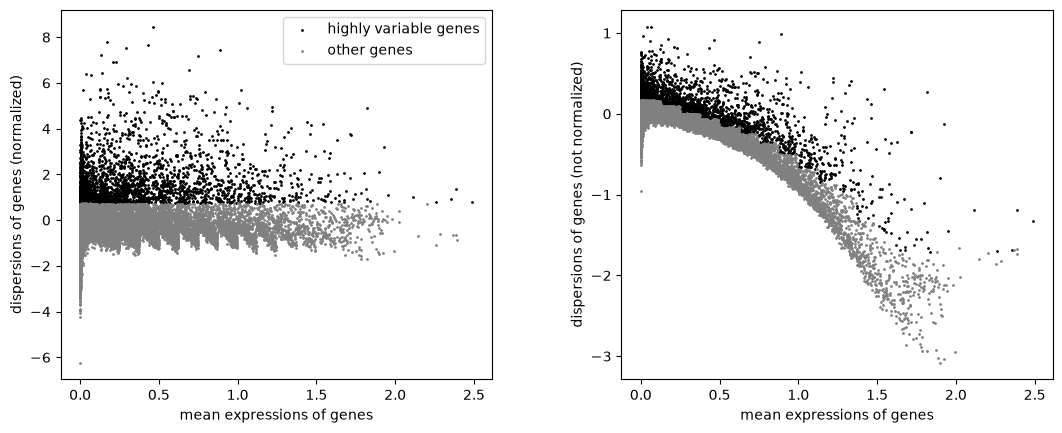

Checkpoint saved: 02_normalised.h5ad


In [9]:
# Normalise to 10,000 counts per spot
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.layers["normalised"] = adata.X.copy()

print(f"Normalisation complete. X range: {adata.X.min():.2f} – {adata.X.max():.2f}")

# HVG selection
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=PARAMS["n_hvgs"],
    flavor=PARAMS["hvg_flavor"],
    subset=False
)
n_hvg = adata.var["highly_variable"].sum()
print(f"Highly variable genes: {n_hvg} / {adata.n_vars}")

sc.pl.highly_variable_genes(adata, save=f"_{SAMPLE_ID}_hvg.png", show=True)

adata.write(f"{CKPT_DIR}/02_normalised.h5ad")
print("Checkpoint saved: 02_normalised.h5ad")

---
## 6. Dimensionality reduction

computing PCA
    with n_comps=50
    finished (0:00:01)


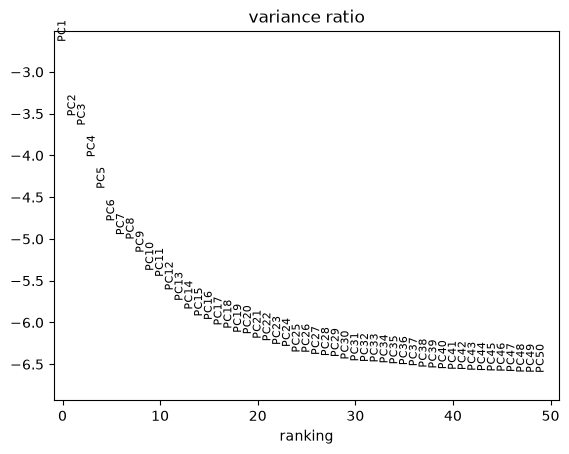

computing neighbors
    using 'X_pca' with n_pcs = 30
    finished (0:00:10)
computing UMAP
    finished (0:00:04)


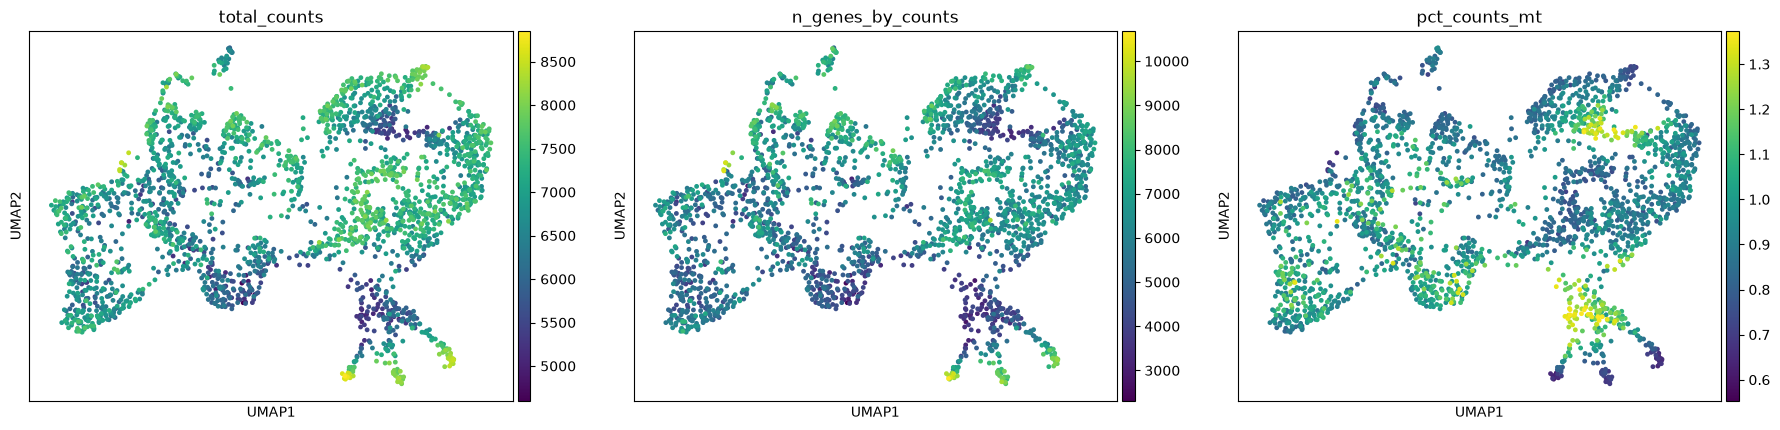

Checkpoint saved: 03_reduced.h5ad


In [10]:
sc.pp.scale(adata, max_value=10)

sc.tl.pca(
    adata,
    n_comps=PARAMS["n_pcs"],
    use_highly_variable=True,
    svd_solver="arpack",
    random_state=SEED
)

sc.pl.pca_variance_ratio(
    adata, n_pcs=PARAMS["n_pcs"], log=True,
    save=f"_{SAMPLE_ID}_elbow.png", show=True
)

sc.pp.neighbors(
    adata,
    n_pcs=PARAMS["n_pcs_use"],
    n_neighbors=PARAMS["n_neighbours"],
    random_state=SEED
)

sc.tl.umap(adata, random_state=SEED)

# UMAP coloured by QC metrics — spot residual artefacts
sc.pl.umap(
    adata,
    color=["total_counts", "n_genes_by_counts", "pct_counts_mt"],
    ncols=3,
    save=f"_{SAMPLE_ID}_umap_qc.png",
    show=True
)

adata.write(f"{CKPT_DIR}/03_reduced.h5ad")
print("Checkpoint saved: 03_reduced.h5ad")

---
## 7. Clustering

running Leiden clustering
    finished (0:00:00)
  res=0.3  :   7 clusters
running Leiden clustering
    finished (0:00:00)
  res=0.5  :  10 clusters
running Leiden clustering
    finished (0:00:00)
  res=0.8  :  15 clusters
running Leiden clustering
    finished (0:00:00)
  res=1.0  :  16 clusters


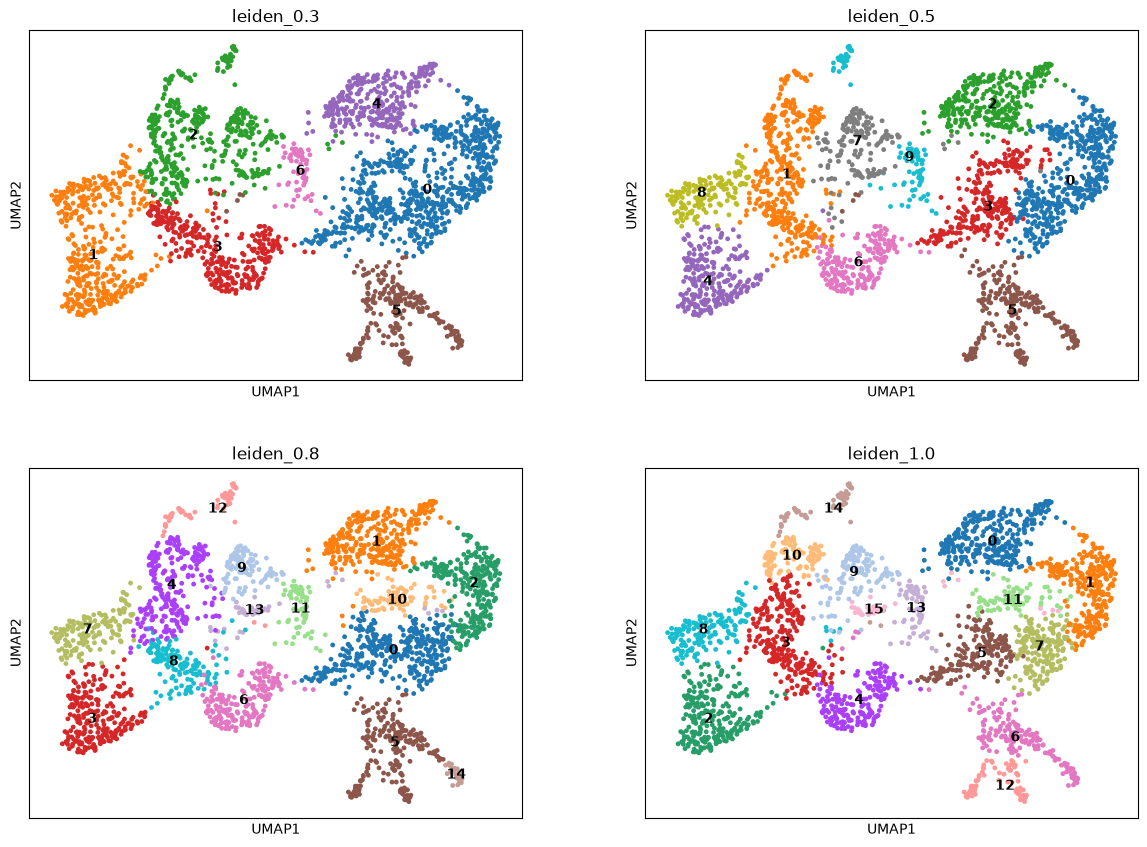

In [11]:
resolution_results = {}

for res in PARAMS["leiden_resolutions"]:
    key = f"leiden_{res}"
    sc.tl.leiden(adata, resolution=res, key_added=key, random_state=SEED)
    n_clusters = adata.obs[key].nunique()
    resolution_results[res] = n_clusters
    print(f"  res={res:<5}: {n_clusters:>3} clusters")

sc.pl.umap(
    adata,
    color=[f"leiden_{r}" for r in PARAMS["leiden_resolutions"]],
    ncols=2,
    legend_loc="on data",
    save=f"_{SAMPLE_ID}_umap_leiden_resolutions.png",
    show=True
)

In [12]:
print("Resolution summary:")
for res, n in resolution_results.items():
    print(f"  res={res}: {n} clusters")

Resolution summary:
  res=0.3: 7 clusters
  res=0.5: 10 clusters
  res=0.8: 15 clusters
  res=1.0: 16 clusters


Final clustering: resolution=0.5, 10 clusters


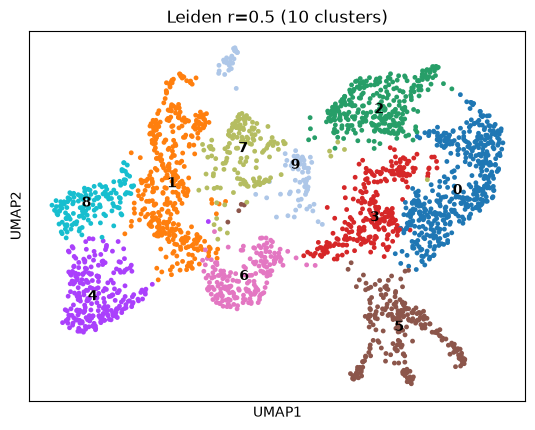

Checkpoint saved: 04_clustered.h5ad


In [13]:
# Set final resolution 
final_key = f"leiden_{PARAMS['leiden_final']}"
adata.obs["leiden"] = adata.obs[final_key].copy()
n_final_clusters = adata.obs["leiden"].nunique()

print(f"Final clustering: resolution={PARAMS['leiden_final']}, {n_final_clusters} clusters")

sc.pl.umap(
    adata,
    color="leiden",
    legend_loc="on data",
    title=f"Leiden r={PARAMS['leiden_final']} ({n_final_clusters} clusters)",
    save=f"_{SAMPLE_ID}_umap_final_leiden.png",
    show=True
)

adata.write(f"{CKPT_DIR}/04_clustered.h5ad")
print("Checkpoint saved: 04_clustered.h5ad")

---
## 8. Spatial visualisation

Map clusters and gene expression back to tissue coordinates.
This is the key step that differentiates spatial from scRNA analysis —
spatially coherent clusters suggest biologically meaningful regions.

In [14]:
adata.uns.pop('leiden_colors', None)

array(['#1f77b4', '#ff7f0e', '#279e68', '#d62728', '#aa40fc', '#8c564b',
       '#e377c2', '#b5bd61', '#17becf', '#aec7e8', '#ffbb78', '#98df8a',
       '#ff9896', '#c5b0d5', '#c49c94'], dtype=object)

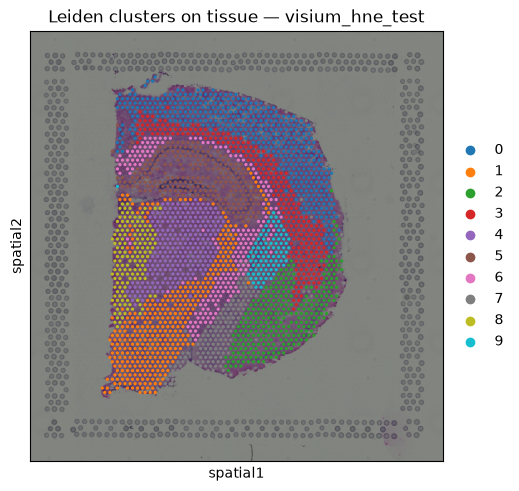

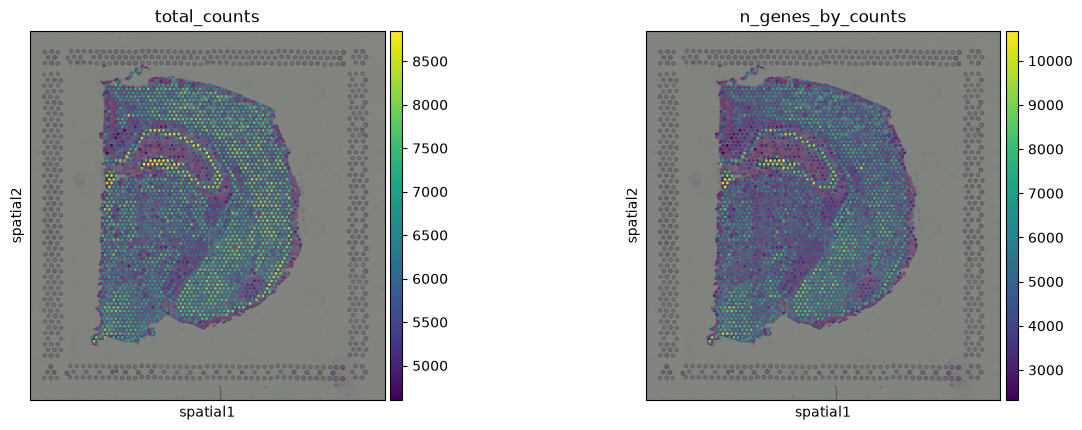

In [15]:
# Clusters on tissue
sq.pl.spatial_scatter(
    adata,
    color="leiden",
    title=f"Leiden clusters on tissue — {SAMPLE_ID}",
    img_res_key="lowres",
    save=f"_{SAMPLE_ID}_spatial_clusters.png",
)

# QC metrics on tissue (post-filter sanity check)
sq.pl.spatial_scatter(
    adata,
    color=["total_counts", "n_genes_by_counts"],
    ncols=2,
    img_res_key="lowres",
    save=f"_{SAMPLE_ID}_spatial_counts.png",
)

---
## 9. Spatially variable genes

Identifies genes whose expression varies significantly across spatial positions.
These are candidates for defining tissue regions or gradients.

`sq.gr.spatial_autocorr` with `mode='moran'` computes Moran's I — 
a spatial autocorrelation statistic. Genes with high I and low p-value
are spatially structured.

INFO     Creating graph using `None` transform and `1` libraries.                                                  
Adding `adata.obsp['spatial_connectivities']`
       `adata.obsp['spatial_distances']`
       `adata.uns['spatial_neighbors']`
Calculating moran's statistic for `100` permutations using `4` core(s)


  0%|          | 0/100 [00:00<?, ?/s]

/opt/conda/envs/env_spatial/lib/python3.12/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/opt/conda/envs/env_spatial/lib/python3.12/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/opt/conda/envs/env_spatial/lib/python3.12/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/opt/conda/envs/env_spatial/lib/python3.12/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/opt/conda/envs/env_spatial/lib/python3.12/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/opt/conda/envs/env_spatial/lib/python3.12/site-packages/docrep

Adding `adata.uns['moranI']`
Finish (0:00:49)
Top 10 spatially variable genes:
              I  pval_norm  pval_norm_fdr_bh
Slc17a7  0.7633        0.0               0.0
Nrgn     0.7403        0.0               0.0
Mbp      0.7370        0.0               0.0
Cck      0.7206        0.0               0.0
Itpka    0.7199        0.0               0.0
Baiap3   0.6945        0.0               0.0
Agt      0.6933        0.0               0.0
Tcf7l2   0.6800        0.0               0.0
Prkcd    0.6684        0.0               0.0
Camk2n1  0.6652        0.0               0.0


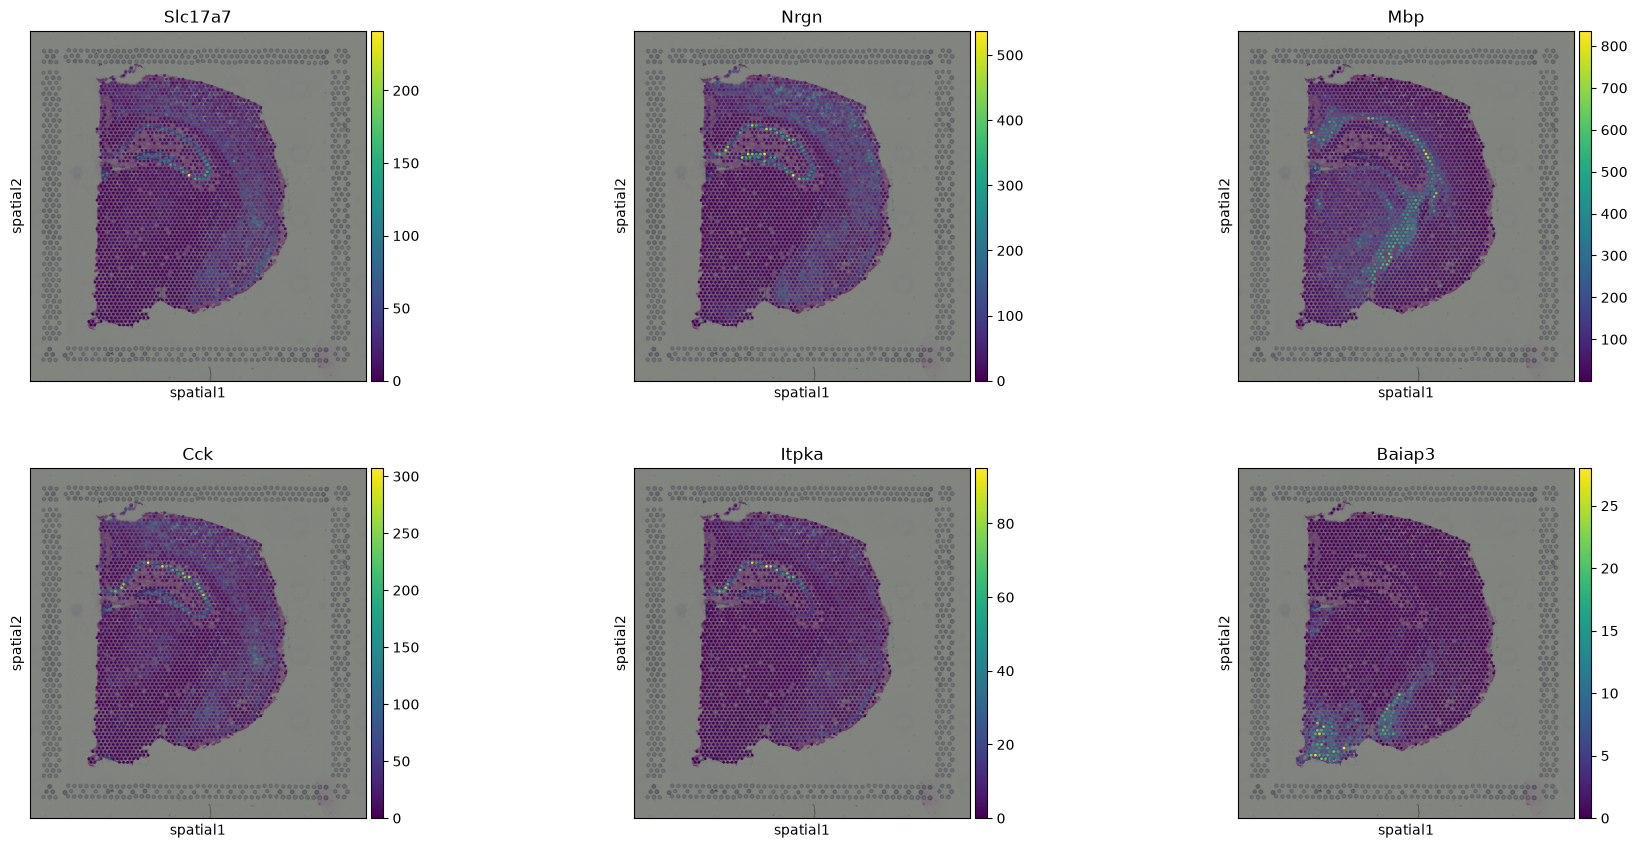

In [16]:
# Build spatial neighbour graph
sq.gr.spatial_neighbors(adata, n_rings=PARAMS["n_rings"], coord_type="grid")

# Compute spatial autocorrelation (Moran's I)
# This identifies genes with non-random spatial expression patterns
sq.gr.spatial_autocorr(
    adata,
    mode="moran",
    n_perms=100,
    n_jobs=4,
    genes=adata.var_names[adata.var["highly_variable"]].tolist()
)

# Extract top spatially variable genes
svgs = adata.uns["moranI"].sort_values("I", ascending=False)
print(f"Top 10 spatially variable genes:")
print(svgs.head(10)[["I", "pval_norm", "pval_norm_fdr_bh"]].round(4))

# Plot top 6 SVGs on tissue
top_svgs = svgs.head(6).index.tolist()
sq.pl.spatial_scatter(
    adata,
    color=top_svgs,
    ncols=3,
    img_res_key="lowres",
    save=f"_{SAMPLE_ID}_top_svgs.png",
)

---
## 10. Neighbourhood enrichment

Tests whether clusters are spatially co-localised more than expected by chance.
Positive scores indicate two clusters appear next to each other frequently.
Negative scores indicate avoidance.

Calculating neighborhood enrichment using `1` core(s)


  0%|          | 0/1000 [00:00<?, ?/s]

Adding `adata.uns['leiden_nhood_enrichment']`
Finish (0:00:00)


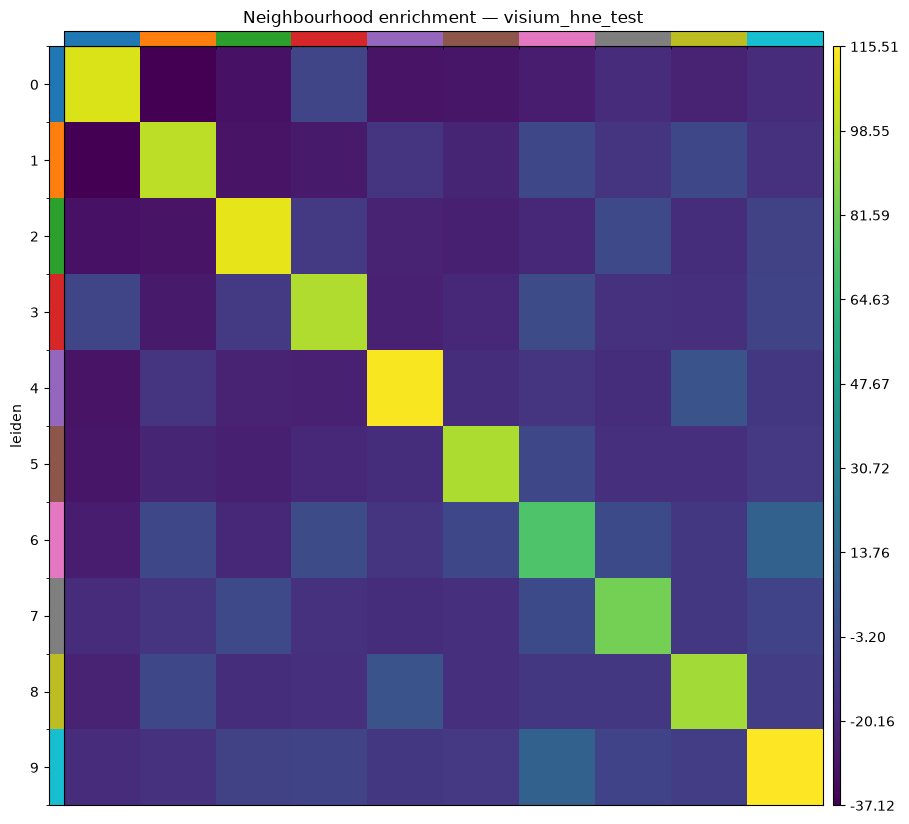

In [17]:
sq.gr.nhood_enrichment(adata, cluster_key="leiden")

sq.pl.nhood_enrichment(
    adata,
    cluster_key="leiden",
    title=f"Neighbourhood enrichment — {SAMPLE_ID}",
    figsize=(8, 8),
    save=f"_{SAMPLE_ID}_nhood_enrichment.png",
    show=True
)

---
## 11. Marker identification

Same approach as scRNA — Wilcoxon rank-sum test per cluster.
Run on normalised (not scaled) counts.

ranking genes
    finished (0:00:04)


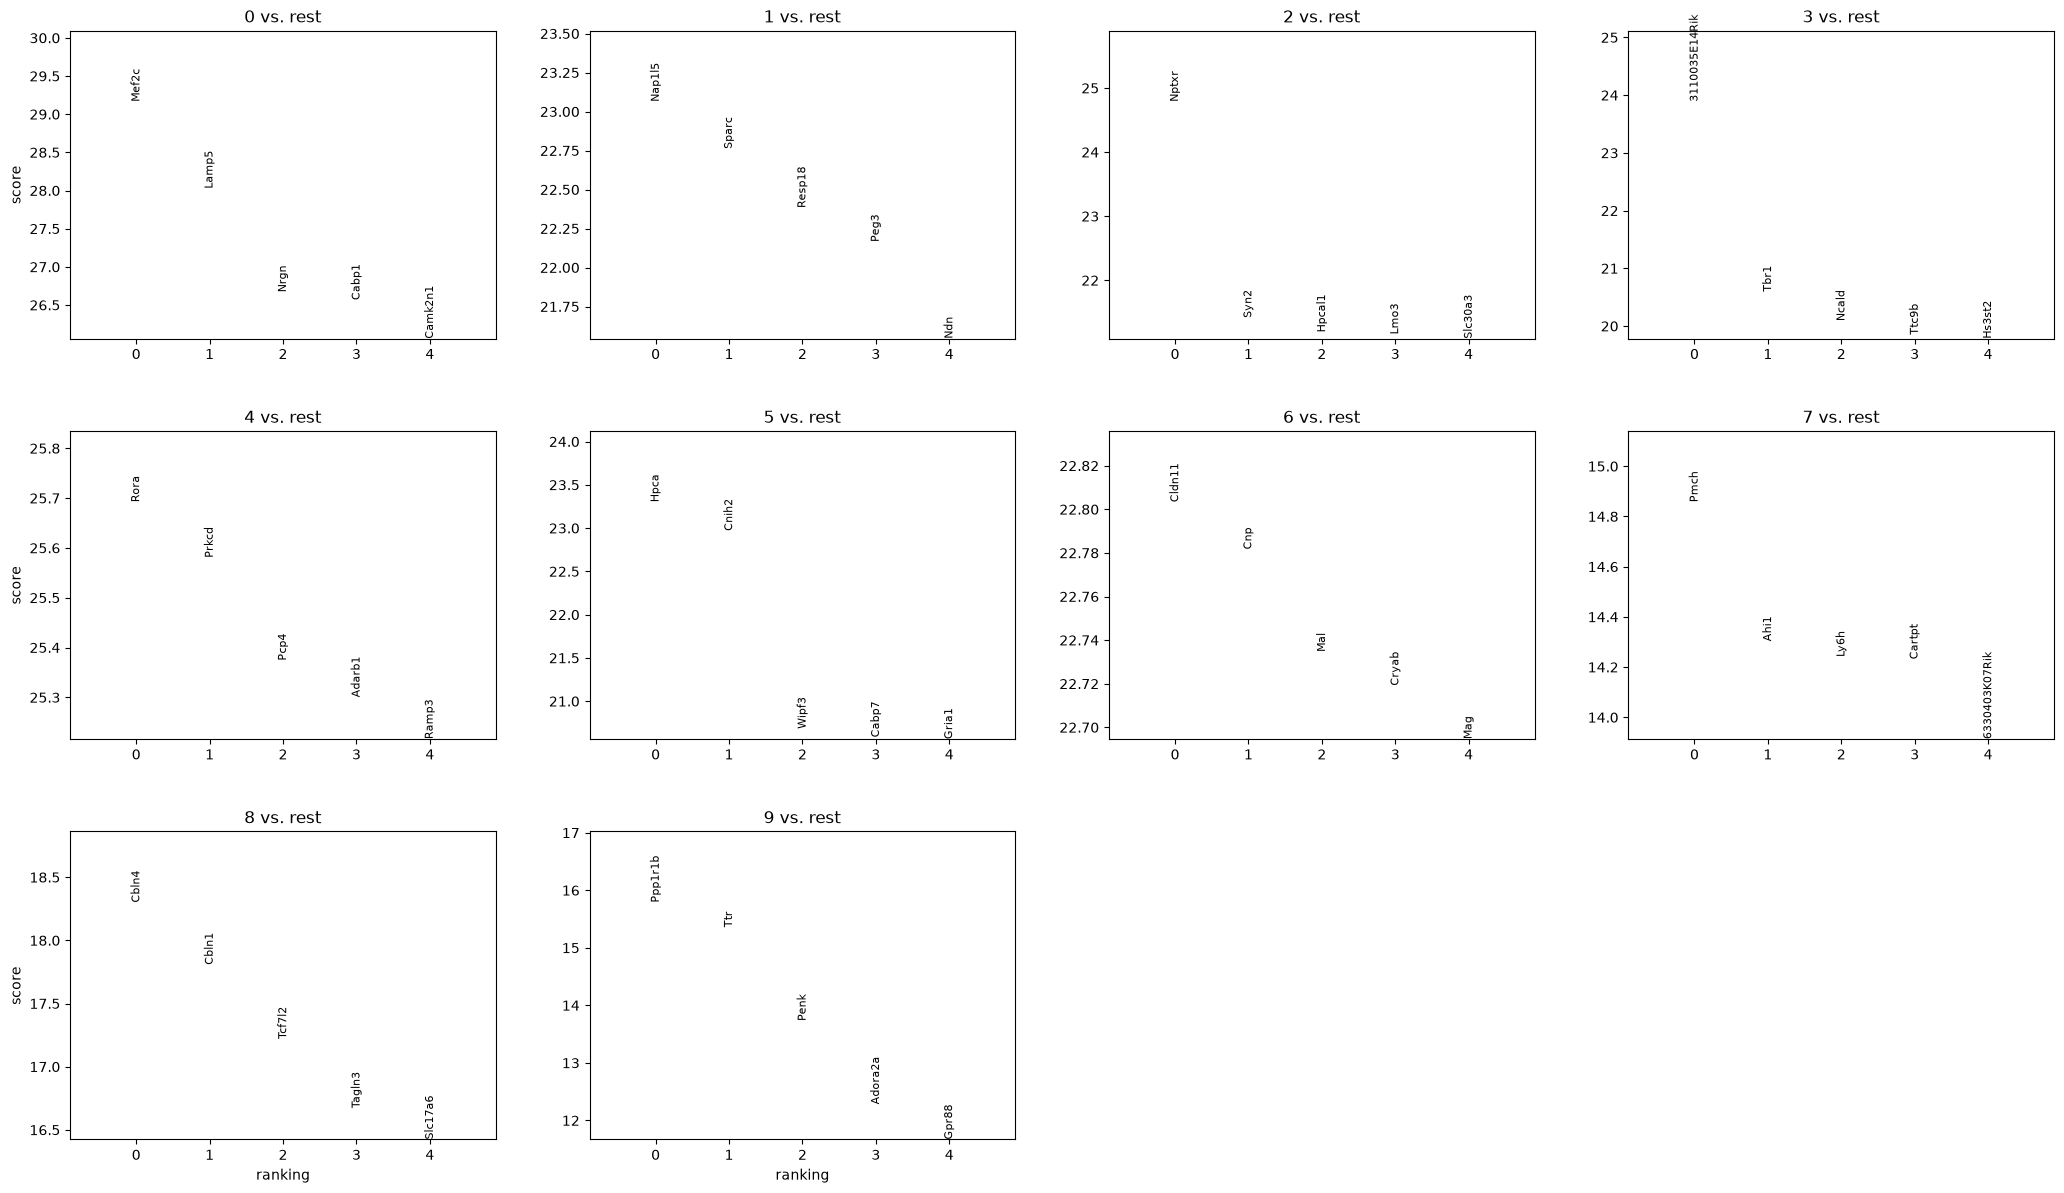

Significant markers: 8792
     group          names     scores  logfoldchanges          pvals      pvals_adj
0        0          Mef2c  29.163034        1.336361  5.710333e-187  1.032314e-182
1        0          Lamp5  28.024727        2.262228  8.120659e-173  7.340264e-169
942      1         Nap1l5  23.062866        0.630763  1.092701e-117  3.950769e-114
943      1          Sparc  22.760899        0.774886  1.119287e-114  2.890640e-111
2037     2          Nptxr  24.785723        1.212391  1.278001e-135  2.310370e-131
2038     2           Syn2  21.413406        0.692282  1.002150e-101   9.058436e-98
2723     3  3110035E14Rik  23.885422        1.853959  4.341512e-126  7.848586e-122
2724     3           Tbr1  20.595863        2.087668   2.989160e-94   2.701902e-90
3531     4           Rora  25.691889        2.241260  1.440241e-145  2.603668e-141
3532     4          Prkcd  25.580252        3.427668  2.530659e-144  2.287463e-140
4448     5           Hpca  23.299656        1.219264  4.46895

In [18]:
# Restore normalised counts for DE
adata.X = adata.layers["normalised"].copy()

sc.tl.rank_genes_groups(
    adata,
    groupby="leiden",
    method="wilcoxon",
    key_added="markers",
    use_raw=False,
    corr_method="benjamini-hochberg"
)

sc.pl.rank_genes_groups(
    adata, n_genes=5, key="markers", sharey=False,
    save=f"_{SAMPLE_ID}_markers.png", show=True
)

markers_df = sc.get.rank_genes_groups_df(
    adata, group=None, key="markers", pval_cutoff=0.05, log2fc_min=0.5
)
markers_df.to_csv(f"{BASE_DIR}/markers_{SAMPLE_ID}.csv", index=False)
print(f"Significant markers: {len(markers_df)}")
print(markers_df.groupby('group').head(2).to_string())

---
## 12. Automated annotation — CellTypist

For spatial data, CellTypist annotates each spot independently.
`majority_voting=True` smooths predictions within Leiden clusters.

Note: standard Visium spots contain multiple cells — annotation reflects
the dominant cell type per spot, not a single cell identity.

In [19]:
if PARAMS["run_celltypist"]:
    import celltypist
    from celltypist import models

    model = models.Model.load(model=PARAMS["celltypist_model"])

    adata_ct = adata.copy()
    adata_ct.X = adata_ct.layers["normalised"].copy()

    predictions = celltypist.annotate(
        adata_ct,
        model=model,
        majority_voting=True,
        over_clustering="leiden"
    )

    adata.obs["celltypist_cell_type"] = predictions.predicted_labels["majority_voting"]
    adata.obs["celltypist_conf_score"] = predictions.probability_matrix.max(axis=1).values

    print("CellTypist annotation summary:")
    print(adata.obs["celltypist_cell_type"].value_counts().to_string())

    # Spatial annotation map
    sq.pl.spatial_scatter(
        adata,
        color="celltypist_cell_type",
        title=f"CellTypist annotation — {SAMPLE_ID}",
        img_res_key="lowres",
        save=f"_{SAMPLE_ID}_celltypist_spatial.png",
    )

    sc.pl.umap(
        adata,
        color=["celltypist_cell_type", "celltypist_conf_score"],
        ncols=2,
        save=f"_{SAMPLE_ID}_celltypist_umap.png",
        show=True
    )
else:
    print("CellTypist skipped.")
    adata.obs["celltypist_cell_type"] = "unknown"
    adata.obs["celltypist_conf_score"] = np.nan

CellTypist skipped.


---
## 13. Summary export

In [22]:
adata.write(f"{CKPT_DIR}/05_annotated.h5ad")
print("Checkpoint saved: 05_annotated.h5ad")

summary = {
    "metadata": {
        "sample_id" : PARAMS["sample_id"],
        "date"      : PARAMS["date"],
        "author"    : PARAMS["author"],
        "kernel"    : "env_spatial",
        "notebook"  : "02_spatial_analysis.ipynb",
        "modality"  : PARAMS["modality"],
    },
    "params": PARAMS,
    "qc": {
        "thresholds"        : {k: round(float(v), 2) for k, v in thresholds.items()},
        "spot_counts_table" : cell_counts.to_dict(orient="records"),
        "n_spots_raw"       : int(cell_counts.iloc[0]["n_spots"]),
        "n_spots_final"     : int(adata.n_obs),
        "n_genes_final"     : int(adata.n_vars),
        "n_hvgs"            : int(n_hvg),
    },
    "clustering": {
        "method"             : "leiden",
        "resolutions_tested" : PARAMS["leiden_resolutions"],
        "resolution_final"   : PARAMS["leiden_final"],
        "n_clusters"         : int(n_final_clusters),
        "n_pcs_used"         : PARAMS["n_pcs_use"],
        "n_neighbours"       : PARAMS["n_neighbours"],
    },
    "spatial": {
        "n_svgs_computed"    : int(len(svgs)),
        "top_svg"            : svgs.index[0],
        "top_svg_moran_I"    : round(float(svgs.iloc[0]["I"]), 4),
    },
    "annotation": {
        "method"             : "celltypist" if PARAMS["run_celltypist"] else "none",
        "model"              : PARAMS["celltypist_model"],
        "cell_type_counts"   : adata.obs["celltypist_cell_type"].value_counts().to_dict()
                               if PARAMS["run_celltypist"] else {},
        "median_conf_score"  : round(float(adata.obs["celltypist_conf_score"].median()), 3)
                               if PARAMS["run_celltypist"] else None,
    },
}

summary_path = f"{SUMMARY_DIR}/spatial_summary.json"
with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2, default=str)

print(f"Summary saved: {summary_path}")
print(f"\n── Analysis complete ──────────────────────────────────────")
print(f"  Spots:    {summary['qc']['n_spots_raw']} → {summary['qc']['n_spots_final']}")
print(f"  Genes:    {summary['qc']['n_genes_final']}")
print(f"  HVGs:     {summary['qc']['n_hvgs']}")
print(f"  Clusters: {summary['clustering']['n_clusters']}")
print(f"  Top SVG:  {summary['spatial']['top_svg']} (I={summary['spatial']['top_svg_moran_I']})")

Checkpoint saved: 05_annotated.h5ad
Summary saved: /home/jovyan/work/analyses/visium_hne_test/summaries/spatial_summary.json

── Analysis complete ──────────────────────────────────────
  Spots:    2688 → 2498
  Genes:    18078
  HVGs:     3000
  Clusters: 10
  Top SVG:  Slc17a7 (I=0.7633)


---
## 14. Software versions

In [21]:
import session_info2
session_info2.session_info()

Package,Version
numpy,2.5.4
pandas,3.0.6
scanpy,1.12.4
squidpy,1.8.2
matplotlib,3.11.2
seaborn,0.13.2
scipy,1.18.1
anndata,0.13.4
Component,Info
Python,"3.12.15 (main, Oct 13 2026, 16:52:04) [GCC 15.3.0]"
